# Projeto Final — Robô Autônomo V.I.N.I. (Navegação Urbana no CoppeliaSim)

Este notebook concentra o pipeline completo de navegação autônoma do triciclo **V.I.N.I.**, dividido em 4 módulos integrados:

1. **Módulo 1 — Mapeamento e Calibração (Occupancy Grid 2D em Dupla Camada)**:
   - **Camada de Navegação (`grid_rrt.npy`)**: Livre (`0`) apenas no asfalto das vias e rotatórias (com inflação C-Space para segurança contra o meio-fio); Ocupado (`1`) em calçadas, canteiros, grama e prédios.
   - **Camada de Obstáculos Físicos (`grid_mcl.npy`)**: Ocupado (`1`) apenas nos **20 prédios físicos 3D** que possuem altura e refletem o feixe do LiDAR 2D (`fastHokuyo`); Livre (`0`) no asfalto, calçadas e grama.
   - **Calibração e Alinhamento 180° (`map_config.json`, `mapa_rrt_pb_coppelia.png`)**: Alinhamento métrico automático com o Occupancy Grid de referência do CoppeliaSim (`0,08153 m/px`, erro máx. `2,8 cm`).
2. **Módulo 2 — Localização Probabilística (MCL / Filtro de Partículas)**:
   - Pré-cálculo do *Likelihood Field* (mapa de distância até prédios 3D), classe vetorizada `ParticleFilterMCL` e validação em tempo real com o `fastHokuyo` no CoppeliaSim.
3. **Módulo 3 — Planejamento de Caminhos (Reward-Guided RRT\*)**:
   - Integração calibrada do planejador em `hydrone-sim-python/` sobre o mapa urbano alinhado ao CoppeliaSim, com visualização da árvore/rota e exportação dos *waypoints* para o controle.
4. **Módulo 4 — Controle Cinemático (Modelo Bicicleta / Ackermann — Path Follower)** *(próxima etapa)*

![Pipeline da Arquitetura](mapeamento/pipeline_arquitetura.png)

---
## Módulo 1: Mapeamento e Geração das Grades de Ocupação (`grid_rrt` e `grid_mcl`)

### Célula 1: Importar bibliotecas e carregar a imagem do cenário urbano

Mapa carregado com sucesso! Dimensões da matriz: W=976 cols x H=1024 rows


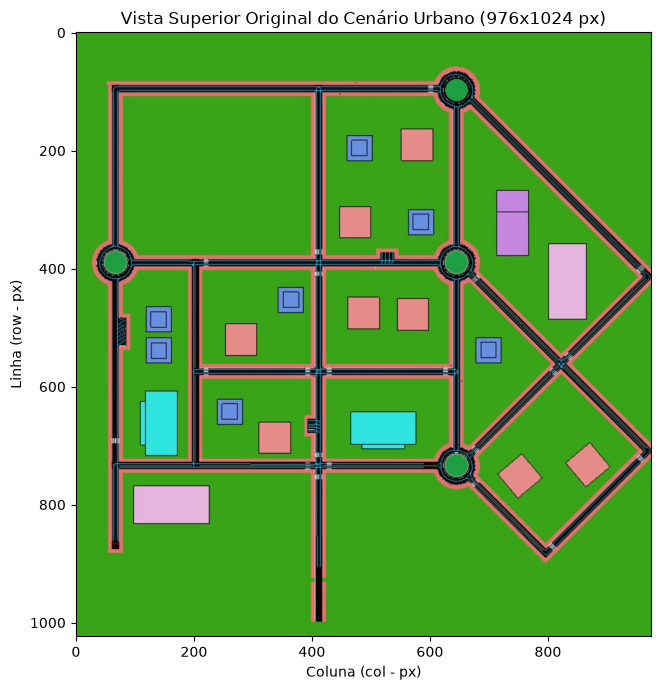

In [1]:
import os
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Garante que a pasta mapeamento/ seja encontrada tanto rodando da raiz quanto de subpastas
BASE_DIR = os.path.abspath(".")
if os.path.basename(BASE_DIR) == "mapeamento":
    MAP_DIR = BASE_DIR
else:
    MAP_DIR = os.path.join(BASE_DIR, "mapeamento")

os.makedirs(MAP_DIR, exist_ok=True)
IMG_PATH = os.path.join(MAP_DIR, "mapa_cidade.jpg")

img_bgr = cv2.imread(IMG_PATH)
if img_bgr is None:
    raise FileNotFoundError(f"Imagem não encontrada em: {IMG_PATH}")

img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
H, W, _ = img_rgb.shape
print(f"Mapa carregado com sucesso! Dimensões da matriz: W={W} cols x H={H} rows")

plt.figure(figsize=(7, 7))
plt.imshow(img_rgb)
plt.title(f"Vista Superior Original do Cenário Urbano ({W}x{H} px)")
plt.xlabel("Coluna (col - px)")
plt.ylabel("Linha (row - px)")
plt.tight_layout()
plt.show()

### Célula 2: Segmentação por Cor e Topologia (Asfalto Contínuo vs. Prédios 3D)

- **Separação dos Prédios (`grid_mcl.npy`)**: Na imagem do cenário, alguns prédios têm a mesma cor salmão das calçadas. Porém, **todos os 20 prédios** estão fisicamente isolados dentro dos quarteirões de grama, enquanto as calçadas formam um único componente conexo colado à malha viária. Combinando limiarização da grama com análise de componentes conexas (`cv2.connectedComponentsWithStats`), separamos com 100% de precisão os **20 prédios 3D** (azuis, salmão, ciano, roxo e rosa) sem confundir nenhum pixel de calçada.
- **Separação do Asfalto**: Dentro da malha viária, removemos as calçadas salmão e aplicamos fechamento morfológico (`cv2.MORPH_CLOSE`) para absorver as faixas de pedestres brancas e linhas-guia azuis, tornando o asfalto **100% contínuo**.

In [2]:
# Conversão para int16 evita overflow de uint8 em comparações de canais RGB
rgb_i16 = img_rgb.astype(np.int16)

# 1. Máscara da grama (fundo verde e ilhas centrais das rotatórias)
grass_mask = (
    (rgb_i16[:, :, 1] > 110)
    & (rgb_i16[:, :, 1] > rgb_i16[:, :, 0] + 40)
    & (rgb_i16[:, :, 1] > rgb_i16[:, :, 2] + 50)
)
non_grass = (~grass_mask).astype(np.uint8)

# 2. Análise topológica de componentes conexas do que não é grama:
#    - O maior componente (~172 mil px) é a malha viária + calçadas.
#    - Os outros 20 componentes (área > 500 px) são exatamente os 20 prédios físicos 3D!
num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(non_grass, connectivity=8)
comp_areas = [
    (i, stats[i, cv2.CC_STAT_AREA])
    for i in range(1, num_labels)
    if stats[i, cv2.CC_STAT_AREA] > 500
]
comp_areas.sort(key=lambda x: -x[1])

road_comp_id = comp_areas[0][0]
building_ids = [idx for idx, _ in comp_areas[1:]]

# Camada de Obstáculos Físicos para o LiDAR / MCL (1 = Prédio 3D, 0 = Livre para o laser)
grid_mcl = np.isin(labels, building_ids).astype(np.uint8)
kernel_predios = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
grid_mcl = cv2.morphologyEx(grid_mcl, cv2.MORPH_CLOSE, kernel_predios)

# 3. Isolar o Asfalto dentro da malha viária (removendo as calçadas salmão)
road_network_mask = (labels == road_comp_id)
sidewalk_color = (
    (rgb_i16[:, :, 0] > 115)
    & (rgb_i16[:, :, 0] > rgb_i16[:, :, 1] + 25)
    & (rgb_i16[:, :, 0] > rgb_i16[:, :, 2] + 15)
)
raw_asphalt = (road_network_mask & (~sidewalk_color)).astype(np.uint8)

# Abertura 3x3 (remove borda de 1px de compressão JPEG) + Fechamento 7x7 (une faixas de pedestres e marcações)
k_open = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
k_close = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
asphalt_clean = cv2.morphologyEx(raw_asphalt, cv2.MORPH_OPEN, k_open)
asphalt_clean = cv2.morphologyEx(asphalt_clean, cv2.MORPH_CLOSE, k_close)

# Seleciona o componente conexo único da pista de asfalto
n_a, lbl_a, st_a, _ = cv2.connectedComponentsWithStats(asphalt_clean, connectivity=8)
main_asphalt_id = 1 + int(np.argmax(st_a[1:, cv2.CC_STAT_AREA]))
asphalt_mask = (lbl_a == main_asphalt_id).astype(np.uint8)
asphalt_mask = cv2.morphologyEx(asphalt_mask, cv2.MORPH_CLOSE, k_close)

print(f"Prédios 3D detectados para o MCL: {len(building_ids)} prédios ({grid_mcl.sum()} pixels ocupados)")
print(f"Asfalto contínuo extraído: {asphalt_mask.sum()} pixels livres antes da inflação C-Space")

Prédios 3D detectados para o MCL: 20 prédios (75507 pixels ocupados)
Asfalto contínuo extraído: 82732 pixels livres antes da inflação C-Space


### Célula 3: Inflação de Obstáculos (C-Space) para a Camada de Navegação (`grid_rrt.npy`)

Dilatamos os obstáculos (ou equivalentemente erodimos a máscara livre de asfalto) por um raio `INFLATION_RADIUS_PX` equivalente à metade da largura do VINI + margem de segurança, garantindo que o planejador **RRT** nunca gere rotas raspando no meio-fio das calçadas ou das rotatórias.

In [3]:
# Raio de inflação em pixels (ajustável: 2 px mantém ~6-8 px de corredor central livre e 100% conectado)
INFLATION_RADIUS_PX = 2

# Mapa binário bruto de navegação (0 = Asfalto Livre, 1 = Calçada/Grama/Prédios)
grid_rrt_raw = (1 - asphalt_mask).astype(np.uint8)

if INFLATION_RADIUS_PX > 0:
    k_size = 2 * INFLATION_RADIUS_PX + 1
    k_inflate = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_size, k_size))
    # Dilatar os obstáculos (1) equivale a inflar o C-Space para longe do meio-fio
    grid_rrt = cv2.dilate(grid_rrt_raw, k_inflate)
else:
    grid_rrt = grid_rrt_raw.copy()

# Verificação topológica: garante que a pista livre (grid_rrt == 0) continua 100% conectada
free_rrt = (grid_rrt == 0).astype(np.uint8)
n_conn, _, st_conn, _ = cv2.connectedComponentsWithStats(free_rrt, connectivity=8)
largest_free = st_conn[1:, cv2.CC_STAT_AREA].max() if n_conn > 1 else 0
pct_conn = 100.0 * largest_free / max(1, free_rrt.sum())

print(f"Raio de inflação C-Space aplicado: {INFLATION_RADIUS_PX} px (kernel {2*INFLATION_RADIUS_PX+1}x{2*INFLATION_RADIUS_PX+1})")
print(f"Pixels navegáveis após inflação (grid_rrt == 0): {free_rrt.sum()} px ({pct_conn:.1f}% em malha única conectada)")

Raio de inflação C-Space aplicado: 2 px (kernel 5x5)
Pixels navegáveis após inflação (grid_rrt == 0): 55666 px (100.0% em malha única conectada)


### Célula 4: Calibração Mundo Real (CoppeliaSim) $\leftrightarrow$ Pixels da Grade

Para converter qualquer coordenada $(x, y)$ do CoppeliaSim em índices $(col, row)$ da matriz $(H \times W)$:

$$col = \left\lfloor \frac{x - x_{\min}}{\text{res}} \right\rfloor, \qquad row = (H - 1) - \left\lfloor \frac{y - y_{\min}}{\text{res}} \right\rfloor$$

Abaixo detectamos automaticamente os centros em pixels das **4 rotatórias** da imagem para servir como marcos visuais de calibração rápida com o CoppeliaSim.

In [4]:
# Detecta automaticamente os centros em pixels (col, row) das 4 ilhas verdes das rotatórias
g_num, g_labels, g_stats, g_centroids = cv2.connectedComponentsWithStats(grass_mask.astype(np.uint8), connectivity=8)
rotatorias_px = []
for i in range(1, g_num):
    area = g_stats[i, cv2.CC_STAT_AREA]
    if 800 <= area <= 3500:
        col_c, row_c = g_centroids[i]
        rotatorias_px.append((float(col_c), float(row_c)))

# Ordena por linha (row) e coluna (col)
rotatorias_px.sort(key=lambda p: (round(p[1] / 100), p[0]))
nomes_rotatorias = [
    "Rotatória Superior Direita",
    "Rotatória Central Esquerda",
    "Rotatória Central Direita",
    "Rotatória Inferior Direita",
]
marcos_px = dict(zip(nomes_rotatorias, rotatorias_px))
print("Marcos visuais detectados na imagem (col, row):")
for nome, (c, r) in marcos_px.items():
    print(f"  - {nome}: col = {c:.1f} px, row = {r:.1f} px")


def calibrar_por_dois_pontos(p1_world, p1_px, p2_world, p2_px, height=H, width=W):
    """
    Calcula resolution (m/pixel), origin_x (x_min) e origin_y (y_min)
    a partir de dois marcos conhecidos: (x, y) no CoppeliaSim e (col, row) na imagem.
    """
    x1, y1 = p1_world
    c1, r1 = p1_px
    x2, y2 = p2_world
    c2, r2 = p2_px

    res_x = abs(x2 - x1) / max(1e-6, abs(c2 - c1))
    res_y = abs(y2 - y1) / max(1e-6, abs(r2 - r1))
    res = 0.5 * (res_x + res_y)

    origin_x = x1 - c1 * res
    origin_y = y1 - ((height - 1) - r1) * res
    return {
        "resolution": float(res),
        "resolution_x": float(res_x),
        "resolution_y": float(res_y),
        "origin_x": float(origin_x),
        "origin_y": float(origin_y),
        "width": int(width),
        "height": int(height),
    }


# -------------------------------------------------------------------------
# CONFIGURAÇÃO DE CALIBRAÇÃO (Ajuste p1_world e p2_world com os valores lidos no CoppeliaSim)
# Por padrão, assumimos um terreno urbano de 50m de largura centrado em (0, 0),
# ou você pode descomentar calibrar_por_dois_pontos() com as posições reais de 2 rotatórias!
# -------------------------------------------------------------------------
USAR_CALIBRACAO_DOIS_PONTOS = False

if USAR_CALIBRACAO_DOIS_PONTOS:
    # Exemplo: substitua pelas coordenadas (x, y) lidas no CoppeliaSim para as duas rotatórias
    p1_world = (7.20, 20.10)   # (x, y) da Rotatória Superior Direita no CoppeliaSim
    p2_world = (-21.60, 5.60)  # (x, y) da Rotatória Central Esquerda no CoppeliaSim
    map_config = calibrar_por_dois_pontos(
        p1_world, marcos_px["Rotatória Superior Direita"],
        p2_world, marcos_px["Rotatória Central Esquerda"],
    )
else:
    # Escala padrão: ~0.05 m/pixel (5 cm por pixel) centrada na origem do CoppeliaSim
    DEFAULT_RES = 0.05
    map_config = {
        "resolution": DEFAULT_RES,
        "origin_x": -(W * DEFAULT_RES) / 2.0,
        "origin_y": -(H * DEFAULT_RES) / 2.0,
        "width": int(W),
        "height": int(H),
    }

map_config["inflation_radius_px"] = int(INFLATION_RADIUS_PX)
map_config["inflation_radius_m"] = float(INFLATION_RADIUS_PX * map_config["resolution"])
map_config["landmarks_px"] = {k: {"col": round(v[0], 2), "row": round(v[1], 2)} for k, v in marcos_px.items()}


def world_to_grid(x, y, cfg=map_config):
    """Converte coordenada (x, y) [metros] do CoppeliaSim para (col, row) [pixels] da matriz."""
    res = cfg["resolution"]
    col = int(np.floor((x - cfg["origin_x"]) / res))
    row = (cfg["height"] - 1) - int(np.floor((y - cfg["origin_y"]) / res))
    return col, row


def grid_to_world(col, row, cfg=map_config):
    """Converte pixel (col, row) da matriz para coordenada (x, y) [metros] no CoppeliaSim."""
    res = cfg["resolution"]
    x = cfg["origin_x"] + (col + 0.5) * res
    y = cfg["origin_y"] + ((cfg["height"] - 1 - row) + 0.5) * res
    return float(x), float(y)


print("\nConfiguração de Calibração (map_config):")
print(json.dumps(map_config, indent=2, ensure_ascii=False))

Marcos visuais detectados na imagem (col, row):
  - Rotatória Superior Direita: col = 645.3 px, row = 97.5 px
  - Rotatória Central Esquerda: col = 67.3 px, row = 389.5 px
  - Rotatória Central Direita: col = 645.2 px, row = 389.3 px
  - Rotatória Inferior Direita: col = 645.0 px, row = 733.3 px

Configuração de Calibração (map_config):
{
  "resolution": 0.05,
  "origin_x": -24.400000000000002,
  "origin_y": -25.6,
  "width": 976,
  "height": 1024,
  "inflation_radius_px": 2,
  "inflation_radius_m": 0.1,
  "landmarks_px": {
    "Rotatória Superior Direita": {
      "col": 645.33,
      "row": 97.49
    },
    "Rotatória Central Esquerda": {
      "col": 67.28,
      "row": 389.51
    },
    "Rotatória Central Direita": {
      "col": 645.17,
      "row": 389.33
    },
    "Rotatória Inferior Direita": {
      "col": 644.99,
      "row": 733.3
    }
  }
}


### Célula 5: Exportação Padronizada (`grid_rrt.npy`, `grid_mcl.npy`, `map_config.json`) e Visualização

Salva os arquivos padronizados na pasta `mapeamento/` para consumo direto pelos módulos de **MCL**, **RRT** e **Controle Cinemático**, e plota as camadas lado a lado.

Arquivos exportados com sucesso em '/workspaces/Project_VINI/mapeamento':
  - grid_rrt.npy   shape=(1024, 976), dtype=uint8 (0=Livre, 1=Ocupado)
  - grid_mcl.npy   shape=(1024, 976), dtype=uint8 (0=Livre, 1=Prédio 3D)
  - map_config.json


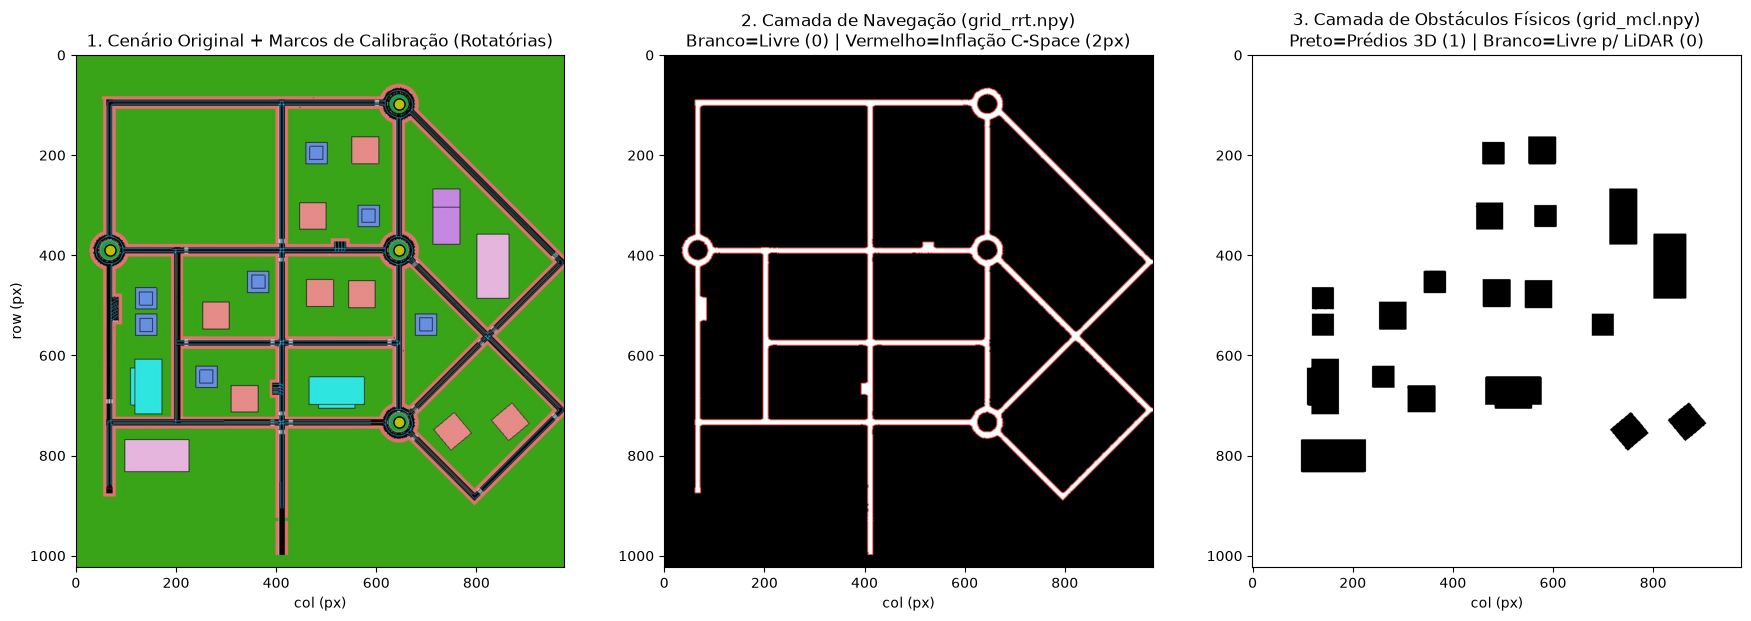

In [5]:
rrt_path = os.path.join(MAP_DIR, "grid_rrt.npy")
mcl_path = os.path.join(MAP_DIR, "grid_mcl.npy")
cfg_path = os.path.join(MAP_DIR, "map_config.json")
fig_path = os.path.join(MAP_DIR, "visualizacao_mapas.png")

np.save(rrt_path, grid_rrt)
np.save(mcl_path, grid_mcl)
with open(cfg_path, "w", encoding="utf-8") as f:
    json.dump(map_config, f, indent=2, ensure_ascii=False)

print(f"Arquivos exportados com sucesso em '{MAP_DIR}':")
print(f"  - grid_rrt.npy   shape={grid_rrt.shape}, dtype={grid_rrt.dtype} (0=Livre, 1=Ocupado)")
print(f"  - grid_mcl.npy   shape={grid_mcl.shape}, dtype={grid_mcl.dtype} (0=Livre, 1=Prédio 3D)")
print(f"  - map_config.json")

# Visualização comparativa das 3 representações
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Painel 1: Imagem original + Marcos das 4 rotatórias
axes[0].imshow(img_rgb)
for nome, (c, r) in marcos_px.items():
    axes[0].plot(c, r, "yo", markersize=8, markeredgecolor="black")
axes[0].set_title("1. Cenário Original + Marcos de Calibração (Rotatórias)")
axes[0].set_xlabel("col (px)")
axes[0].set_ylabel("row (px)")

# Painel 2: Camada de Navegação RRT (mostrando C-Space inflado vs pista livre)
# Visualização colorida: Branco = Pista Livre (0), Vermelho = Margem C-Space inflada, Preto = Obstáculo (1)
vis_rrt = np.zeros((H, W, 3), dtype=np.uint8)
vis_rrt[grid_rrt == 0] = [255, 255, 255]                    # Livre após inflação (Branco)
cspace_band = (grid_rrt_raw == 0) & (grid_rrt == 1)
vis_rrt[cspace_band] = [255, 90, 90]                        # Margem C-Space junto ao meio-fio (Vermelho)
axes[1].imshow(vis_rrt)
axes[1].set_title(f"2. Camada de Navegação (grid_rrt.npy)\nBranco=Livre (0) | Vermelho=Inflação C-Space ({INFLATION_RADIUS_PX}px)")
axes[1].set_xlabel("col (px)")

# Painel 3: Camada de Obstáculos Físicos MCL (1 = Prédios 3D que refletem o LiDAR)
axes[2].imshow(1 - grid_mcl, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("3. Camada de Obstáculos Físicos (grid_mcl.npy)\nPreto=Prédios 3D (1) | Branco=Livre p/ LiDAR (0)")
axes[2].set_xlabel("col (px)")

plt.tight_layout()
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()

### Célula 6: Calibração Automática com o Mapa Exploratório do CoppeliaSim, Alinhamento 180° e Exportação P&B

Esta célula utiliza o Occupancy Grid exploratório de referência gerado no CoppeliaSim (`mapeamento/Occupancy_Grid_-_Terminal_Update.png`, escala real de $84\text{ m} \times 84\text{ m}$ centrada em $(0, 0)$ com $0{,}10\text{ m/célula}$) para:

1. Recortar exatamente a área interna de $84\text{ m} \times 84\text{ m}$ e detectar o centro das **4 rotatórias** em coordenadas reais do simulador $(x, y)$.
2. Exportar a camada de navegação em PNG preto e branco puro na orientação original (`mapa_rrt_pb.png`) e rotacionar `grid_rrt.npy` e `grid_mcl.npy` em **180°** para alinhamento exato com o sistema de coordenadas do CoppeliaSim (`mapa_rrt_pb_coppelia.png`).
3. Calcular `resolution`, `origin_x` e `origin_y` exatos a partir das 4 rotatórias, atualizar `map_config.json` (incluindo `inflation_radius_m`, `landmarks_px` e `landmarks_world_m`) e exibir lado a lado a validação da sobreposição e o mapa P&B exportado para o RRT.

Quadrado recortado: 371 x 371 px (equivale a 84.0m x 84.0m)
Resolução calibrada: 0.08153 m/pixel (res_x=0.08155, res_y=0.08151)
Origem calibrada: origin_x=-39.5724 m, origin_y=-41.7430 m
Erro residual por rotatória:
  - Rotatória Superior Esquerda: mundo=(-12.64, +18.08) m | previsto=(-12.63, +18.08) m | erro=1.3 cm
  - Rotatória Central Esquerda: mundo=(-12.65, -9.93) m | previsto=(-12.64, -9.96) m | erro=2.8 cm
  - Rotatória Inferior Esquerda: mundo=(-12.63, -33.75) m | previsto=(-12.65, -33.75) m | erro=2.4 cm
  - Rotatória Central Direita: mundo=(+34.48, -9.97) m | previsto=(+34.48, -9.95) m | erro=2.6 cm

Arquivos atualizados em /workspaces/Project_VINI/mapeamento:
  - grid_rrt.npy (rotacionado 180° — CoppeliaSim)
  - grid_mcl.npy (rotacionado 180° — CoppeliaSim)
  - map_config.json (calibrado)
  - mapa_rrt_pb.png (P&B puro — orientação original)
  - mapa_rrt_pb_coppelia.png (P&B puro — orientação CoppeliaSim 180°)


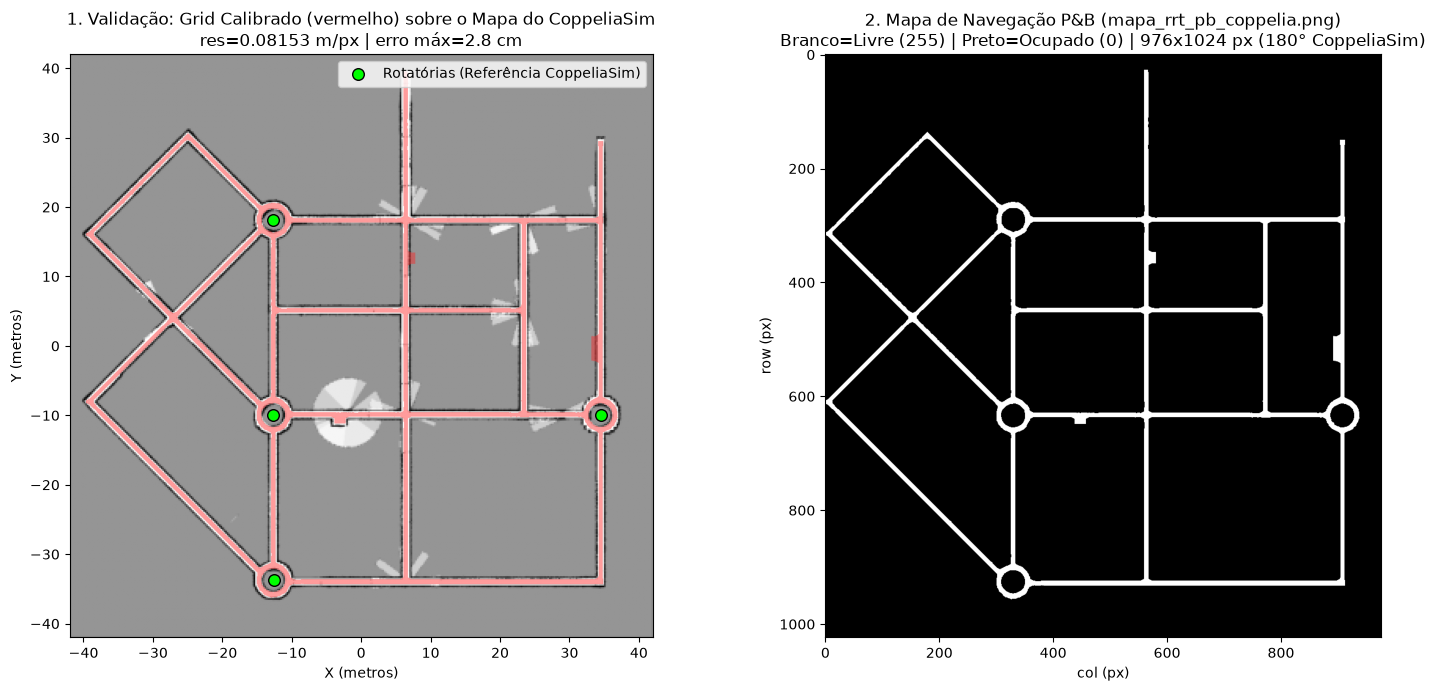

In [6]:
import os
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# Garante o caminho correto da pasta mapeamento/ mesmo executando esta célula isoladamente
BASE_DIR = os.path.abspath(".")
MAP_DIR = BASE_DIR if os.path.basename(BASE_DIR) == "mapeamento" else os.path.join(BASE_DIR, "mapeamento")

ref_img_path = os.path.join(MAP_DIR, "Occupancy_Grid_-_Terminal_Update.png")
rrt_path = os.path.join(MAP_DIR, "grid_rrt.npy")
mcl_path = os.path.join(MAP_DIR, "grid_mcl.npy")
cfg_path = os.path.join(MAP_DIR, "map_config.json")

# 1. Carregar o Occupancy Grid de referência do CoppeliaSim e recortar o quadrado exato de 84m x 84m
img_ref = cv2.imread(ref_img_path, cv2.IMREAD_GRAYSCALE)
assert img_ref is not None, f"Salve a imagem de referência em {ref_img_path}"

# Encontra o maior contorno quadrado (o mapa) ignorando a barra de cores lateral
mask_nao_branco = (img_ref < 250).astype(np.uint8) * 255
contours, _ = cv2.findContours(mask_nao_branco, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

melhor_box = None
maior_area = 0
for cnt in contours:
    x, y, w, h = cv2.boundingRect(cnt)
    ratio = w / float(h)
    if 0.90 <= ratio <= 1.10 and (w * h) > maior_area:
        maior_area = w * h
        melhor_box = (x, y, w, h)

assert melhor_box is not None, "Não foi possível localizar o quadrado do mapa na imagem de referência."
bx, by, bw, bh = melhor_box
# Remove 2px da borda preta do plot para ficar exatamente com o interior de 84m x 84m
map_crop = img_ref[by + 2 : by + bh - 2, bx + 2 : bx + bw - 2]
Hc, Wc = map_crop.shape
print(f"Quadrado recortado: {Wc} x {Hc} px (equivale a 84.0m x 84.0m)")

# 2. Detectar as 4 ilhas cinzas das rotatórias no mapa de referência do CoppeliaSim
# As ruas são brancas (>230) e as ilhas internas das rotatórias são cinzas (~128) cercadas por branco
mask_nao_rua = (map_crop < 220).astype(np.uint8)
num_labels, labels_ref, stats_ref, centroids_ref = cv2.connectedComponentsWithStats(mask_nao_rua)

ilhas = []
for i in range(1, num_labels):
    area = stats_ref[i, cv2.CC_STAT_AREA]
    w_i = stats_ref[i, cv2.CC_STAT_WIDTH]
    h_i = stats_ref[i, cv2.CC_STAT_HEIGHT]
    # Filtro geométrico para pegar apenas as 4 ilhas circulares das rotatórias
    if 80 < area < 2000 and 0.75 <= (w_i / float(h_i)) <= 1.35:
        cx, cy = centroids_ref[i]
        # Conversão direta para metros do CoppeliaSim: X in [-42, 42], Y in [-42, 42]
        wx = -42.0 + ((cx + 0.5) / Wc) * 84.0
        wy =  42.0 - ((cy + 0.5) / Hc) * 84.0
        ilhas.append((cx, cy, wx, wy))

assert len(ilhas) == 4, f"Esperava 4 rotatórias, mas encontrei {len(ilhas)}. Ajuste o filtro de área."

# Ordena as 4 rotatórias de referência: 3 na coluna esquerda (topo -> baixo) e 1 na direita
ilhas_ord = sorted(ilhas, key=lambda p: p[0])            # ordena por X (col)
rot_dir_ref = ilhas_ord[-1]                              # a mais à direita (Central Direita)
rot_esq_ref = sorted(ilhas_ord[:-1], key=lambda p: p[1]) # 3 da esquerda: Sup, Cen, Inf

nomes_rotatorias_coppelia = [
    "Rotatória Superior Esquerda",
    "Rotatória Central Esquerda",
    "Rotatória Inferior Esquerda",
    "Rotatória Central Direita",
]

world_pts = np.array([
    [rot_esq_ref[0][2], rot_esq_ref[0][3]], # Superior Esquerda (m)
    [rot_esq_ref[1][2], rot_esq_ref[1][3]], # Central Esquerda (m)
    [rot_esq_ref[2][2], rot_esq_ref[2][3]], # Inferior Esquerda (m)
    [rot_dir_ref[2],    rot_dir_ref[3]],    # Central Direita (m)
])

# 3. Carregar grids e config e aplicar rotação de 180° de forma idempotente (evita girar 2x se re-executar)
with open(cfg_path, "r", encoding="utf-8") as f:
    cfg = json.load(f)

grid_rrt = np.load(rrt_path)
grid_mcl = np.load(mcl_path)
H, W = grid_rrt.shape

ja_rotacionado = bool(cfg.get("rotated_180_coppelia", False))

if not ja_rotacionado:
    # Exporta versão P&B pura na orientação original antes de rotacionar 180°
    img_pb_orig = ((1 - grid_rrt) * 255).astype(np.uint8)
    cv2.imwrite(os.path.join(MAP_DIR, "mapa_rrt_pb.png"), img_pb_orig)

    # Rotaciona os grids em 180° para alinhar com o sistema de coordenadas do CoppeliaSim
    grid_rrt = np.rot90(grid_rrt, 2).copy()
    grid_mcl = np.rot90(grid_mcl, 2).copy()

    # Transforma as coordenadas em pixels das 4 rotatórias pela rotação de 180°: (W-1-col, H-1-row)
    raw_lms = [(v["col"], v["row"]) for v in cfg["landmarks_px"].values()]
    rot_lms = [(W - 1 - col, H - 1 - row) for (col, row) in raw_lms]
else:
    print("Aviso: grids já estavam rotacionados em 180° (execução idempotente mantida).")
    rot_lms = [(v["col"], v["row"]) for v in cfg["landmarks_px"].values()]

# Ordena as 4 rotatórias do grid na mesma convenção: 3 à esquerda (topo -> baixo) e 1 à direita
lms_ord = sorted(rot_lms, key=lambda p: p[0])
lm_dir = lms_ord[-1]
lms_esq = sorted(lms_ord[:-1], key=lambda p: p[1])

px_pts = np.array([
    [lms_esq[0][0], lms_esq[0][1]], # Superior Esquerda (px)
    [lms_esq[1][0], lms_esq[1][1]], # Central Esquerda (px)
    [lms_esq[2][0], lms_esq[2][1]], # Inferior Esquerda (px)
    [lm_dir[0],     lm_dir[1]],     # Central Direita (px)
])

# 4. Calcular resolução (m/px) e origem (origin_x, origin_y) coerentes com grid_to_world/world_to_grid
res_x = (world_pts[3, 0] - world_pts[1, 0]) / (px_pts[3, 0] - px_pts[1, 0])
res_y = (world_pts[0, 1] - world_pts[2, 1]) / (px_pts[2, 1] - px_pts[0, 1])
resolution = float((res_x + res_y) / 2.0)

origin_x = float(np.mean(world_pts[:, 0] - (px_pts[:, 0] + 0.5) * resolution))
origin_y = float(np.mean(world_pts[:, 1] - (H - 0.5 - px_pts[:, 1]) * resolution))

# Calcula erro residual nas 4 rotatórias
erros_m = []
print(f"Resolução calibrada: {resolution:.5f} m/pixel (res_x={res_x:.5f}, res_y={res_y:.5f})")
print(f"Origem calibrada: origin_x={origin_x:.4f} m, origin_y={origin_y:.4f} m")
print("Erro residual por rotatória:")
for nome, (px_c, px_r), (wx, wy) in zip(nomes_rotatorias_coppelia, px_pts, world_pts):
    pred_x = origin_x + (px_c + 0.5) * resolution
    pred_y = origin_y + (H - 0.5 - px_r) * resolution
    err = float(np.hypot(pred_x - wx, pred_y - wy))
    erros_m.append(err)
    print(f"  - {nome}: mundo=({wx:+.2f}, {wy:+.2f}) m | previsto=({pred_x:+.2f}, {pred_y:+.2f}) m | erro={err*100:.1f} cm")

# 5. Salvar grids rotacionados, map_config.json calibrado e PNG P&B limpo para o planejador RRT
np.save(rrt_path, grid_rrt)
np.save(mcl_path, grid_mcl)

img_pb_coppelia = ((1 - grid_rrt) * 255).astype(np.uint8)
cv2.imwrite(os.path.join(MAP_DIR, "mapa_rrt_pb_coppelia.png"), img_pb_coppelia)

cfg["resolution"] = resolution
cfg["resolution_x"] = float(res_x)
cfg["resolution_y"] = float(res_y)
cfg["origin_x"] = origin_x
cfg["origin_y"] = origin_y
cfg["inflation_radius_m"] = float(cfg.get("inflation_radius_px", 2) * resolution)
cfg["rotated_180_coppelia"] = True
cfg["calibration_source"] = "Occupancy_Grid_-_Terminal_Update.png (84.0m x 84.0m, 0.10m/cell)"
cfg["max_calibration_error_m"] = round(max(erros_m), 4)
cfg["landmarks_px"] = {
    nome: {"col": round(float(c), 2), "row": round(float(r), 2)}
    for nome, (c, r) in zip(nomes_rotatorias_coppelia, px_pts)
}
cfg["landmarks_world_m"] = {
    nome: {"x": round(float(wx), 3), "y": round(float(wy), 3)}
    for nome, (wx, wy) in zip(nomes_rotatorias_coppelia, world_pts)
}

with open(cfg_path, "w", encoding="utf-8") as f:
    json.dump(cfg, f, indent=2, ensure_ascii=False)

# Atualiza map_config e funções auxiliares em memória para os próximos módulos
map_config = cfg


def world_to_grid(x, y, cfg=map_config):
    """Converte coordenada (x, y) [metros] do CoppeliaSim para (col, row) [pixels] da matriz."""
    res = cfg["resolution"]
    col = int(np.floor((x - cfg["origin_x"]) / res))
    row = (cfg["height"] - 1) - int(np.floor((y - cfg["origin_y"]) / res))
    return col, row


def grid_to_world(col, row, cfg=map_config):
    """Converte pixel (col, row) da matriz para coordenada (x, y) [metros] no CoppeliaSim."""
    res = cfg["resolution"]
    x = cfg["origin_x"] + (col + 0.5) * res
    y = cfg["origin_y"] + ((cfg["height"] - 1 - row) + 0.5) * res
    return float(x), float(y)


print(f"\nArquivos atualizados em {MAP_DIR}:")
print("  - grid_rrt.npy (rotacionado 180° — CoppeliaSim)")
print("  - grid_mcl.npy (rotacionado 180° — CoppeliaSim)")
print("  - map_config.json (calibrado)")
print("  - mapa_rrt_pb.png (P&B puro — orientação original)")
print("  - mapa_rrt_pb_coppelia.png (P&B puro — orientação CoppeliaSim 180°)")

# 6. Validação visual: sobreposição do grid calibrado e visualização do mapa P&B exportado para o RRT
val_path = os.path.join(MAP_DIR, "validacao_calibracao.png")
fig, axes = plt.subplots(1, 2, figsize=(15, 7))

# Painel 1: Sobreposição das ruas livres (vermelho translúcido) sobre o mapa exploratório do CoppeliaSim
axes[0].imshow(map_crop, cmap="gray", extent=[-42, 42, -42, 42])
ruas_overlay = np.ma.masked_where(grid_rrt == 1, np.ones_like(grid_rrt, dtype=float))
axes[0].imshow(
    ruas_overlay,
    cmap=ListedColormap(["#ff2222"]),
    alpha=0.45,
    extent=[origin_x, origin_x + W * resolution, origin_y, origin_y + H * resolution],
)
axes[0].scatter(
    world_pts[:, 0],
    world_pts[:, 1],
    c="lime",
    edgecolors="black",
    s=70,
    zorder=5,
    label="Rotatórias (Referência CoppeliaSim)",
)
axes[0].set_title(
    f"1. Validação: Grid Calibrado (vermelho) sobre o Mapa do CoppeliaSim\n"
    f"res={resolution:.5f} m/px | erro máx={max(erros_m)*100:.1f} cm"
)
axes[0].set_xlabel("X (metros)")
axes[0].set_ylabel("Y (metros)")
axes[0].legend(loc="upper right")

# Painel 2: Visualização do PNG P&B puro exportado na orientação do CoppeliaSim (mapa_rrt_pb_coppelia.png)
axes[1].imshow(img_pb_coppelia, cmap="gray", vmin=0, vmax=255)
axes[1].set_title(
    f"2. Mapa de Navegação P&B (mapa_rrt_pb_coppelia.png)\n"
    f"Branco=Livre (255) | Preto=Ocupado (0) | {W}x{H} px (180° CoppeliaSim)"
)
axes[1].set_xlabel("col (px)")
axes[1].set_ylabel("row (px)")

plt.tight_layout()
plt.savefig(val_path, dpi=150, bbox_inches="tight")
plt.show()

---
## Módulo 2: Localização Probabilística (MCL — Filtro de Partículas)

O algoritmo de **Monte Carlo Localization (MCL)** estima a pose contínua $(x, y, \theta)$ do VINI em tempo real utilizando o modelo de sensor **Likelihood Field** (Thrun et al.) sobre a camada de obstáculos físicos 3D (`grid_mcl.npy`) calibrada no Módulo 1.

### Célula 7: Pré-cálculo do *Likelihood Field* (Mapa de Distância)

Carrega os mapas calibrados do Módulo 1 e transforma `grid_mcl.npy` em um mapa contínuo de distância até o prédio 3D mais próximo (em metros), evitando *raycasting* lento durante a simulação.

Likelihood Field pronto! Shape=(1024, 976) | Distância máx=39.74 m


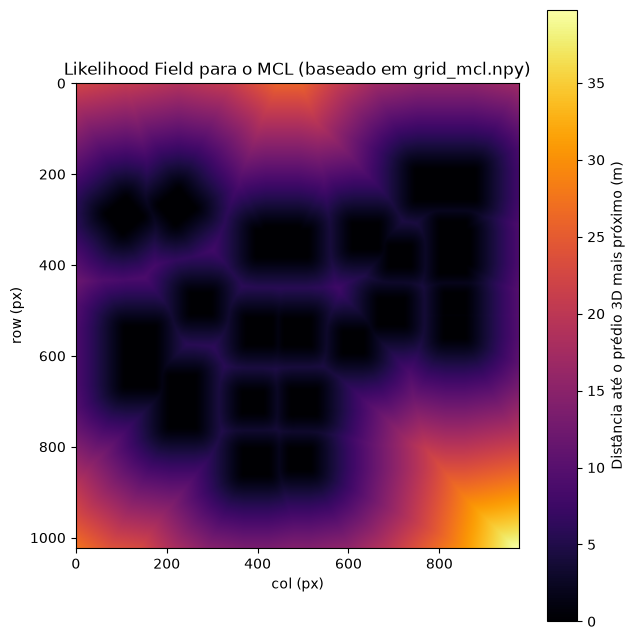

In [7]:
import os
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt

BASE_DIR = os.path.abspath(".")
MAP_DIR = BASE_DIR if os.path.basename(BASE_DIR) == "mapeamento" else os.path.join(BASE_DIR, "mapeamento")

grid_rrt = np.load(os.path.join(MAP_DIR, "grid_rrt.npy"))
grid_mcl = np.load(os.path.join(MAP_DIR, "grid_mcl.npy"))
with open(os.path.join(MAP_DIR, "map_config.json"), "r", encoding="utf-8") as f:
    map_config = json.load(f)

H, W = grid_mcl.shape
RES = map_config["resolution"]
ORIGIN_X = map_config["origin_x"]
ORIGIN_Y = map_config["origin_y"]

# Distance Transform: distância em metros de cada pixel livre até o prédio 3D mais próximo
# (cv2.distanceTransform mede distância até pixels com valor 0, por isso invertemos grid_mcl)
dist_field_m = cv2.distanceTransform((1 - grid_mcl).astype(np.uint8), cv2.DIST_L2, 5) * RES

print(f"Likelihood Field pronto! Shape={dist_field_m.shape} | Distância máx={dist_field_m.max():.2f} m")

plt.figure(figsize=(6.5, 6.5))
plt.imshow(dist_field_m, cmap="inferno")
plt.colorbar(label="Distância até o prédio 3D mais próximo (m)")
plt.title("Likelihood Field para o MCL (baseado em grid_mcl.npy)")
plt.xlabel("col (px)")
plt.ylabel("row (px)")
plt.tight_layout()
plt.savefig(os.path.join(MAP_DIR, "likelihood_field_mcl.png"), dpi=150, bbox_inches="tight")
plt.show()

### Célula 8: Classe `ParticleFilterMCL` (Predição, Atualização e *Low-Variance Resampling*)

Implementa o filtro de partículas totalmente vetorizado em NumPy com dois modos de inicialização: **Tracking** (em torno da pose inicial conhecida) e **Global** (espalhado por todas as ruas livres de `grid_rrt.npy`).

In [8]:
class ParticleFilterMCL:
    def __init__(self, grid_rrt, grid_mcl, dist_field_m, cfg, num_particles=400):
        self.grid_rrt = grid_rrt
        self.grid_mcl = grid_mcl
        self.dist_field_m = dist_field_m
        self.H, self.W = grid_mcl.shape
        self.res = cfg["resolution"]
        self.origin_x = cfg["origin_x"]
        self.origin_y = cfg["origin_y"]
        self.N = num_particles

        # Estado das partículas: [x, y, theta] e pesos normalizados
        self.particles = np.zeros((self.N, 3), dtype=np.float64)
        self.weights = np.full(self.N, 1.0 / self.N, dtype=np.float64)

    def init_tracking(self, x0, y0, theta0, std_xy=0.6, std_theta=np.deg2rad(15)):
        """Inicializa partículas ao redor de uma pose inicial aproximada."""
        self.particles[:, 0] = np.random.normal(x0, std_xy, self.N)
        self.particles[:, 1] = np.random.normal(y0, std_xy, self.N)
        self.particles[:, 2] = np.random.normal(theta0, std_theta, self.N)
        self.particles[:, 2] = np.arctan2(np.sin(self.particles[:, 2]), np.cos(self.particles[:, 2]))
        self.weights.fill(1.0 / self.N)

    def init_global(self):
        """Inicializa partículas uniformemente sobre todas as ruas livres (grid_rrt == 0)."""
        free_rows, free_cols = np.where(self.grid_rrt == 0)
        idx = np.random.choice(len(free_rows), size=self.N, replace=True)
        rows = free_rows[idx]
        cols = free_cols[idx]

        self.particles[:, 0] = self.origin_x + (cols + 0.5) * self.res
        self.particles[:, 1] = self.origin_y + ((self.H - 1 - rows) + 0.5) * self.res
        self.particles[:, 2] = np.random.uniform(-np.pi, np.pi, self.N)
        self.weights.fill(1.0 / self.N)

    def predict(self, delta_s, delta_theta, noise_s=0.05, noise_theta=0.02):
        """
        Modelo de movimento (odometria com ruído gaussiano).
        delta_s: deslocamento linear (m) no passo atual
        delta_theta: variação angular (rad) no passo atual
        """
        std_s = max(0.01, abs(delta_s) * noise_s + 0.005)
        std_th = max(0.005, abs(delta_theta) * noise_theta + 0.003)

        ds = delta_s + np.random.normal(0.0, std_s, self.N)
        dth = delta_theta + np.random.normal(0.0, std_th, self.N)

        theta_mid = self.particles[:, 2] + 0.5 * dth
        self.particles[:, 0] += ds * np.cos(theta_mid)
        self.particles[:, 1] += ds * np.sin(theta_mid)
        self.particles[:, 2] += dth
        self.particles[:, 2] = np.arctan2(np.sin(self.particles[:, 2]), np.cos(self.particles[:, 2]))

    def update(self, laser_pts_local, max_range=5.0, sigma_hit=0.35, z_hit=0.9, z_rand=0.1, subsample=10):
        """
        Atualiza os pesos usando o Likelihood Field sobre os pontos (x, y) locais do fastHokuyo.
        """
        if len(laser_pts_local) == 0:
            return

        # Subamostragem dos feixes para manter o loop rápido em tempo real
        pts = laser_pts_local[::subsample, :2]
        dists = np.hypot(pts[:, 0], pts[:, 1])
        valid = (dists > 0.08) & (dists < (max_range - 0.15))
        pts = pts[valid]

        if len(pts) == 0:
            return

        lx = pts[:, 0]  # (M,)
        ly = pts[:, 1]  # (M,)

        px = self.particles[:, 0][:, None]  # (N, 1)
        py = self.particles[:, 1][:, None]  # (N, 1)
        ct = np.cos(self.particles[:, 2])[:, None]
        st = np.sin(self.particles[:, 2])[:, None]

        # Projeta todos os M feixes para todas as N partículas de uma vez -> (N, M)
        wx = px + lx[None, :] * ct - ly[None, :] * st
        wy = py + lx[None, :] * st + ly[None, :] * ct

        cols = np.floor((wx - self.origin_x) / self.res).astype(np.int32)
        rows = (self.H - 1) - np.floor((wy - self.origin_y) / self.res).astype(np.int32)

        in_bounds = (cols >= 0) & (cols < self.W) & (rows >= 0) & (rows < self.H)
        cols_c = np.clip(cols, 0, self.W - 1)
        rows_c = np.clip(rows, 0, self.H - 1)

        d_obs = self.dist_field_m[rows_c, cols_c]
        d_obs = np.where(in_bounds, d_obs, max_range)

        # Probabilidade do modelo de campo de verossimilhança
        gauss = np.exp(-0.5 * (d_obs / sigma_hit) ** 2) / (np.sqrt(2.0 * np.pi) * sigma_hit)
        p_beam = z_hit * gauss + (z_rand / max_range)
        log_w = np.sum(np.log(np.maximum(p_beam, 1e-12)), axis=1)

        # Penaliza partículas que caíram dentro de prédios físicos
        p_cols = np.clip(np.floor((self.particles[:, 0] - self.origin_x) / self.res).astype(np.int32), 0, self.W - 1)
        p_rows = np.clip((self.H - 1) - np.floor((self.particles[:, 1] - self.origin_y) / self.res).astype(np.int32), 0, self.H - 1)
        inside_building = self.grid_mcl[p_rows, p_cols] == 1
        log_w[inside_building] -= 20.0

        # Normalização numericamente estável
        log_w -= np.max(log_w)
        w_new = self.weights * np.exp(log_w)
        w_sum = np.sum(w_new)

        if w_sum > 1e-15 and np.isfinite(w_sum):
            self.weights = w_new / w_sum
        else:
            self.weights.fill(1.0 / self.N)

    def resample_if_needed(self):
        """Low-Variance Resampling quando o número efetivo de partículas cai abaixo de N/2."""
        n_eff = 1.0 / np.sum(self.weights ** 2)
        if n_eff >= self.N / 2.0:
            return False

        r = np.random.uniform(0.0, 1.0 / self.N)
        positions = r + np.arange(self.N) / self.N
        cumsum = np.cumsum(self.weights)
        cumsum[-1] = 1.0
        idx = np.searchsorted(cumsum, positions)

        self.particles = self.particles[idx].copy()
        self.weights.fill(1.0 / self.N)
        return True

    def get_estimate(self):
        """Retorna a pose estimada (x, y, theta) pela média ponderada."""
        x_est = float(np.sum(self.weights * self.particles[:, 0]))
        y_est = float(np.sum(self.weights * self.particles[:, 1]))
        sin_m = float(np.sum(self.weights * np.sin(self.particles[:, 2])))
        cos_m = float(np.sum(self.weights * np.cos(self.particles[:, 2])))
        theta_est = float(np.arctan2(sin_m, cos_m))
        return x_est, y_est, theta_est


# Teste rápido offline de inicialização e estimativa
_mcl_check = ParticleFilterMCL(grid_rrt, grid_mcl, dist_field_m, map_config, num_particles=400)
_mcl_check.init_tracking(7.10, 12.225, 0.0, std_xy=0.6, std_theta=np.deg2rad(15))
_mcl_check.predict(0.25, 0.02)
_est = _mcl_check.get_estimate()
print(f"Classe ParticleFilterMCL validada com sucesso! Estimativa teste: x={_est[0]:+.2f} m, y={_est[1]:+.2f} m, theta={np.rad2deg(_est[2]):+.1f}°")

Classe ParticleFilterMCL validada com sucesso! Estimativa teste: x=+7.32 m, y=+12.19 m, theta=+1.3°


### Célula 9: Localização Global do MCL em Tempo Real no CoppeliaSim

Conecta ao CoppeliaSim via ZMQ Remote API, inicializa **1.200 partículas** espalhadas por todas as ruas livres da cidade (`init_global()`), lê os pontos locais do LiDAR `fastHokuyo` e exibe a convergência ao vivo (partículas em vermelho, feixes do LiDAR em azul, robô real em verde, estimativa MCL em ciano e trajetória real em preto), salvando *snapshots* automáticos nos passos `0`, `30`, `90` e ao final em `mapeamento/mcl_convergencia_*.png`.

*(Execute esta célula localmente com o CoppeliaSim aberto na cena `simulacao_coppeliasim/Cena_Cidade-VINI.ttt`. Para a janela interativa atualizar ao vivo no Jupyter/VS Code sem criar uma figura nova por passo, descomente `%matplotlib tk` ou `%matplotlib qt` na primeira linha antes de rodar; dirija o VINI e interrompa com **Stop / Ctrl+C** para encerrar.)*

In [ ]:
# Descomente uma das linhas abaixo no Windows/VS Code para atualização ao vivo na mesma janela:
# %matplotlib tk
# %matplotlib qt

import os
import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from coppeliasim_zmqremoteapi_client import RemoteAPIClient

class HokuyoSensorSim:
    def __init__(self, sim, base_name):
        self._sim = sim
        self._base_obj = sim.getObject(base_name)
        self._vision_sensors = [
            sim.getObject(f"{base_name}/sensor1"),
            sim.getObject(f"{base_name}/sensor2"),
        ]

    def get_local_points(self):
        pts = []
        rel_inv = self._sim.getMatrixInverse(self._sim.getObjectMatrix(self._base_obj))
        for vs in self._vision_sensors:
            _, _, u = self._sim.readVisionSensor(vs)
            if u:
                sensor_m = self._sim.getObjectMatrix(vs)
                rel_m = self._sim.multiplyMatrices(rel_inv, sensor_m)
                n_cols, n_rows = int(u[0]), int(u[1])
                for j in range(n_rows):
                    for k in range(n_cols):
                        w = 2 + 4 * (j * n_cols + k)
                        v = [u[w], u[w + 1], u[w + 2]]
                        p = self._sim.multiplyVector(rel_m, v)
                        pts.append([p[0], p[1]])
        return np.array(pts, dtype=np.float64) if pts else np.empty((0, 2))


# 1. Conexão com o CoppeliaSim
client = RemoteAPIClient()
sim = client.require("sim")

vini_handle = sim.getObject("/VINI")
hokuyo = HokuyoSensorSim(sim, "/VINI/base_link_visual/fastHokuyo")

if sim.getSimulationState() == sim.simulation_stopped:
    sim.startSimulation()
    time.sleep(0.5)

# 2. Inicializa o MCL em MODO GLOBAL (partículas espalhadas por toda a cidade)
mcl = ParticleFilterMCL(grid_rrt, grid_mcl, dist_field_m, map_config, num_particles=1200)
mcl.init_global()

pos0 = sim.getObjectPosition(vini_handle, sim.handle_world)
ori0 = sim.getObjectOrientation(vini_handle, sim.handle_world)
prev_x, prev_y, prev_th = pos0[0], pos0[1], ori0[2]

# 3. Configura o gráfico ao vivo
# Fundo: branco = rua livre (grid_rrt == 0), cinza = obstáculo/fora da rua
mapa_visual = np.where(grid_rrt == 0, 255, 145).astype(np.uint8)
extent_world = [ORIGIN_X, ORIGIN_X + W * RES, ORIGIN_Y, ORIGIN_Y + H * RES]

plt.ion()
fig, ax = plt.subplots(figsize=(7.5, 7.5))
ax.imshow(mapa_visual, cmap="gray", vmin=0, vmax=255, extent=extent_world)

# Elementos dinâmicos (atualizados a cada passo sem redesenhar o fundo)
scat_particles = ax.scatter(mcl.particles[:, 0], mcl.particles[:, 1], c="#b22222", s=4, alpha=0.65, zorder=2, label="Partículas (MCL)")
lidar_lines = LineCollection([], colors="blue", linewidths=0.7, alpha=0.75, zorder=3, label="Feixes LiDAR")
ax.add_collection(lidar_lines)
traj_line, = ax.plot([], [], color="black", lw=2.0, zorder=4, label="Trajetória Real")
robot_dot, = ax.plot([prev_x], [prev_y], "o", color="lime", markeredgecolor="black", markersize=8, zorder=5, label="VINI (Real)")
est_dot, = ax.plot([], [], "x", color="cyan", markersize=9, markeredgewidth=2, zorder=6, label="Estimativa MCL")

ax.set_title("Localização Global MCL — Passo 0")
ax.set_xlabel("X (m)")
ax.set_ylabel("Y (m)")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()

hist_gt = [(prev_x, prev_y)]
print("MCL Global ao vivo! Dirija o VINI no CoppeliaSim e aperte Stop (Ctrl+C) para encerrar.")

try:
    step_count = 0
    while True:
        pos = sim.getObjectPosition(vini_handle, sim.handle_world)
        ori = sim.getObjectOrientation(vini_handle, sim.handle_world)
        gt_x, gt_y, gt_th = pos[0], pos[1], ori[2]

        # Odometria incremental
        dx, dy = gt_x - prev_x, gt_y - prev_y
        ds_real = np.hypot(dx, dy)
        if dx * np.cos(prev_th) + dy * np.sin(prev_th) < 0:
            ds_real = -ds_real
        dth_real = np.arctan2(np.sin(gt_th - prev_th), np.cos(gt_th - prev_th))
        prev_x, prev_y, prev_th = gt_x, gt_y, gt_th

        laser_pts = hokuyo.get_local_points()

        # Atualiza o filtro quando o robô se movimenta (ou no início para já filtrar)
        if abs(ds_real) > 0.02 or abs(dth_real) > 0.01 or step_count < 3:
            mcl.predict(ds_real, dth_real, noise_s=0.08, noise_theta=0.05)
            mcl.update(laser_pts, max_range=5.0, sigma_hit=0.35, subsample=8)
            mcl.resample_if_needed()

        est_x, est_y, est_th = mcl.get_estimate()
        err_cm = np.hypot(est_x - gt_x, est_y - gt_y) * 100.0
        hist_gt.append((gt_x, gt_y))

        # Atualiza o gráfico a cada 3 passos para manter fluido
        if step_count % 3 == 0:
            scat_particles.set_offsets(mcl.particles[:, :2])
            robot_dot.set_data([gt_x], [gt_y])
            est_dot.set_data([est_x], [est_y])

            gt_arr = np.array(hist_gt)
            traj_line.set_data(gt_arr[:, 0], gt_arr[:, 1])

            # Projeta os feixes do LiDAR no mundo (subamostrado para visualização limpa)
            if len(laser_pts) > 0:
                pts_vis = laser_pts[::18, :2]
                ct, st = np.cos(gt_th), np.sin(gt_th)
                wx = gt_x + pts_vis[:, 0] * ct - pts_vis[:, 1] * st
                wy = gt_y + pts_vis[:, 0] * st + pts_vis[:, 1] * ct
                segments = [[(gt_x, gt_y), (x_end, y_end)] for x_end, y_end in zip(wx, wy)]
                lidar_lines.set_segments(segments)

            ax.set_title(f"MCL Global — Passo {step_count} | Erro: {err_cm:.1f} cm")
            fig.canvas.draw()
            fig.canvas.flush_events()

            # Salva snapshots automáticos da convergência para o relatório
            if step_count in (0, 30, 90):
                fig.savefig(os.path.join(MAP_DIR, f"mcl_convergencia_passo_{step_count}.png"), dpi=150)

        step_count += 1
        plt.pause(0.02)

except KeyboardInterrupt:
    print("\nVisualização encerrada pelo usuário.")

finally:
    fig.savefig(os.path.join(MAP_DIR, "mcl_convergencia_final.png"), dpi=150)
    plt.ioff()
    plt.show()

---
## Módulo 3: Planejamento de Caminhos (Reward-Guided RRT\*)

Integra diretamente o planejador **Reward-Guided RRT\*** implementado em `hydrone-sim-python/` (mantendo os arquivos originais intactos) ao sistema de coordenadas calibrado do Módulo 1 e do Módulo 2 (MCL).

### Célula 10: Adaptação Calibrada (`CalibratedCityRRT`) e Execução no Cenário `CITY`

- Importa `Reward_Guided_RRT` diretamente de `hydrone-sim-python/` e alinha os limites do ambiente ao `map_config.json` (`[-39.57, 40.00, -41.74, 41.74] m`) sobre `mapeamento/mapa_rrt_pb_coppelia.png`.
- Aplica verificação de colisão sub-pixel (`0,5 * resolution`) ao longo de cada aresta e amostragem guiada na malha viária livre (`grid_rrt == 0`), garantindo rotas 100% livres de colisões nos corredores estreitos da cidade.
- Permite ajustar facilmente `SCENARIO`, `MAX_ITER`, `STEP_M`, ponto inicial (`CUSTOM_START`) e metas (`CUSTOM_GOALS`) no topo da célula.

In [9]:
import os
import sys
import json
import time
import numpy as np

# ── Parâmetros configuráveis do planejador RRT* ───────────────────────────
SCENARIO     = "CITY"   # Cenário definido em hydrone-sim-python/scenerys.yaml
MAX_ITER     = 5000     # Máximo de iterações por fase da árvore
STEP_M       = 1.5      # Passo de expansão da árvore (metros)
RANDOM_SEED  = 42       # Semente para reprodutibilidade (use None para aleatório)

# Opcional: defina coordenadas [x, y] em metros para sobrescrever o scenerys.yaml
# (ex.: usar a pose estimada pelo MCL: CUSTOM_START = [est_x, est_y])
CUSTOM_START = None
CUSTOM_END   = None
CUSTOM_GOALS = None     # Ex.: [[-32.44, 9.01, 110], [-12.64, 18.08, 150]]
# ──────────────────────────────────────────────────────────────────────────

BASE_DIR = os.path.abspath(".")
if os.path.basename(BASE_DIR) == "mapeamento":
    ROOT_DIR = os.path.dirname(BASE_DIR)
else:
    ROOT_DIR = BASE_DIR

MAP_DIR = os.path.join(ROOT_DIR, "mapeamento")
HYDRONE_DIR = os.path.join(ROOT_DIR, "hydrone-sim-python")
PLAN_DIR = os.path.join(ROOT_DIR, "planejamento")
os.makedirs(PLAN_DIR, exist_ok=True)

# Carrega mapa e metadados calibrados do Módulo 1
grid_rrt = np.load(os.path.join(MAP_DIR, "grid_rrt.npy"))
with open(os.path.join(MAP_DIR, "map_config.json"), "r", encoding="utf-8") as f:
    map_config = json.load(f)

H_MAP, W_MAP = grid_rrt.shape
RES_MAP = float(map_config["resolution"])
OX_MAP = float(map_config["origin_x"])
OY_MAP = float(map_config["origin_y"])
CAL_BOUNDS = np.array([OX_MAP, OX_MAP + W_MAP * RES_MAP, OY_MAP, OY_MAP + H_MAP * RES_MAP], dtype=float)
PB_COPPELIA_PATH = os.path.join(MAP_DIR, "mapa_rrt_pb_coppelia.png")

if HYDRONE_DIR not in sys.path:
    sys.path.insert(0, HYDRONE_DIR)

# Pré-calcula coordenadas (x, y) em metros dos pixels navegáveis (grid_rrt == 0)
_free_rows, _free_cols = np.where(grid_rrt == 0)
_free_xs = OX_MAP + (_free_cols + 0.5) * RES_MAP
_free_ys = OY_MAP + ((H_MAP - 1 - _free_rows) + 0.5) * RES_MAP
_n_free = len(_free_xs)

_orig_cwd = os.getcwd()
os.chdir(HYDRONE_DIR)
try:
    from Reward_Guided_RRT import Reward_Guided_RRT, create_goal
    from class_map import Map
    from bias_roulett import Roulette

    class CalibratedCityRRT(Reward_Guided_RRT):
        """
        Subclasse de integração do Reward_Guided_RRT (hydrone-sim-python/) alinhada
        aos parâmetros calibrados do map_config.json e ao mapa_rrt_pb_coppelia.png.
        """
        def __init__(self, max_iter, dist, scenario, start_override=None,
                     end_override=None, goals_override=None, snap_to_free=True):
            super().__init__(max_iter, dist, scenario)
            self.grid_res = RES_MAP
            self.BOUNDS = CAL_BOUNDS.copy()
            self.use_map = True
            self.mapa = Map(
                {"xlim": [self.BOUNDS[0], self.BOUNDS[1]], "ylim": [self.BOUNDS[2], self.BOUNDS[3]]},
                img=PB_COPPELIA_PATH,
            )

            def _snap_to_road(pt, label):
                pt = np.array(pt, dtype=float)
                if not snap_to_free or not self.mapa.collision(pt):
                    return pt
                c0 = int(np.floor((pt[0] - OX_MAP) / RES_MAP))
                r0 = (H_MAP - 1) - int(np.floor((pt[1] - OY_MAP) / RES_MAP))
                d2 = (_free_rows - r0) ** 2 + (_free_cols - c0) ** 2
                bi = int(np.argmin(d2))
                snapped = np.array([_free_xs[bi], _free_ys[bi]], dtype=float)
                print(f"[Calibração] {label} ({pt[0]:+.2f}, {pt[1]:+.2f}) m ajustado para pista livre -> ({snapped[0]:+.2f}, {snapped[1]:+.2f}) m")
                return snapped

            if start_override is not None:
                self.start_pos = np.array(start_override, dtype=float)
            if end_override is not None:
                self.ending_pos = np.array(end_override, dtype=float)

            self.start_pos = _snap_to_road(self.start_pos, "Start")
            self.ending_pos = _snap_to_road(self.ending_pos, "End")

            if goals_override is not None:
                self.goals = [create_goal(np.array(g, dtype=float), i) for i, g in enumerate(goals_override)]
            for g in self.goals:
                g.pos = _snap_to_road(g.pos, f"Goal {g.index}")

            # Custo euclidiano exato e rápido quando não há obstáculos gaussianos no CostMap
            if not self.cost_map.obstacles:
                c0 = self.cost_map.c0
                self.cost_map.travel_cost = (
                    lambda p1, p2, num_steps=1: float(c0 * np.linalg.norm(np.asarray(p2) - np.asarray(p1)))
                )

            # Reconstrói roletas com limites calibrados e amostragem na malha viária livre
            self.out_roulette = Roulette(self.goals, self.cost_map, self.BOUNDS)
            self._start_goal.pos = self.start_pos.copy()
            self._end_goal.pos = self.ending_pos.copy()
            self.ret_roulette = Roulette([self._end_goal], self.cost_map, self.BOUNDS)

            def _sample_free_road(max_attempts=30):
                i = np.random.randint(0, _n_free)
                return np.array([_free_xs[i], _free_ys[i]], dtype=float)

            self.out_roulette.prob_random = 0.85
            self.ret_roulette.prob_random = 0.85
            self.out_roulette._sample_low_cost_pos = _sample_free_road
            self.ret_roulette._sample_low_cost_pos = _sample_free_road

            # Reinicia a árvore na pose inicial calibrada
            self.out_tree = self._new_out_tree(self.start_pos, 0.0)

        def _collision(self, p1, p2):
            """Checagem de colisão sub-pixel (0,5 * resolução) para corredores urbanos estreitos."""
            if self.use_map:
                dist = float(np.linalg.norm(p2 - p1))
                if dist == 0.0:
                    return self.mapa.collision(p1)
                num_steps = max(int(np.ceil(dist / (0.5 * self.grid_res))) + 1, 2)
                xs = np.linspace(p1[0], p2[0], num_steps)
                ys = np.linspace(p1[1], p2[1], num_steps)
                for x, y in zip(xs, ys):
                    if self.mapa.collision([x, y]):
                        return True
                return False
            return super()._collision(p1, p2)

    if RANDOM_SEED is not None:
        np.random.seed(RANDOM_SEED)

    t0 = time.perf_counter()
    rrt_planner = CalibratedCityRRT(
        max_iter=MAX_ITER,
        dist=STEP_M,
        scenario=SCENARIO,
        start_override=CUSTOM_START,
        end_override=CUSTOM_END,
        goals_override=CUSTOM_GOALS,
    )

    total_steps = 0
    max_total_steps = MAX_ITER * max(2, len(rrt_planner.goals) * 2 + 1)
    while not rrt_planner.done and total_steps < max_total_steps:
        rrt_planner.step()
        total_steps += 1

    elapsed_s = time.perf_counter() - t0
    print(f"Planejamento concluído em {total_steps} passos ({elapsed_s:.2f} s) | done={rrt_planner.done}")
    rrt_planner.print_solution()
finally:
    os.chdir(_orig_cwd)

[Calibração] Goal 0 (-33.00, +8.32) m ajustado para pista livre -> (-32.44, +9.01) m


All goals processed. Planning complete.
Planejamento concluído em 2083 passos (1.02 s) | done=True

== Solution ==
  Budget spent    : 130.77 / 600.00  (21.8%)
  Reward collected: 110 / 110  (100.0%)
  Visitation order: START -> [-32.438518030997585, 9.009649838941954] -> START
  Goals unfeasible: []

Going path legs:
  Leg 1: 9 nodes  [ 7.1   12.225] -> [-31.5911777    8.23532488]  budget at end = 64.36  reward at end = 110

Returning path: 7 nodes  budget at end = 130.77/600.0


### Célula 11: Visualização da Rota Planejada e Exportação de Waypoints para o Módulo 4

Reamostra a trajetória encontrada pelo Reward-Guided RRT\* em espaçamento uniforme (`0,5 m`) com orientação tangente $\theta$, plota a árvore explorada e a rota final (ida + retorno) sobre o mapa calibrado em metros, e salva os *waypoints* em `planejamento/waypoints_rrt.csv` e `planejamento/waypoints_rrt.npy` para consumo direto pelo controlador cinemático (Módulo 4).

Waypoints exportados com sucesso em /workspaces/Project_VINI/planejamento:
  - waypoints_rrt.csv : 270 pontos (espaçamento 0.50 m)
  - waypoints_rrt.npy : shape=(270, 3) [x, y, theta]
  - Colisões detectadas nos waypoints: 0/270


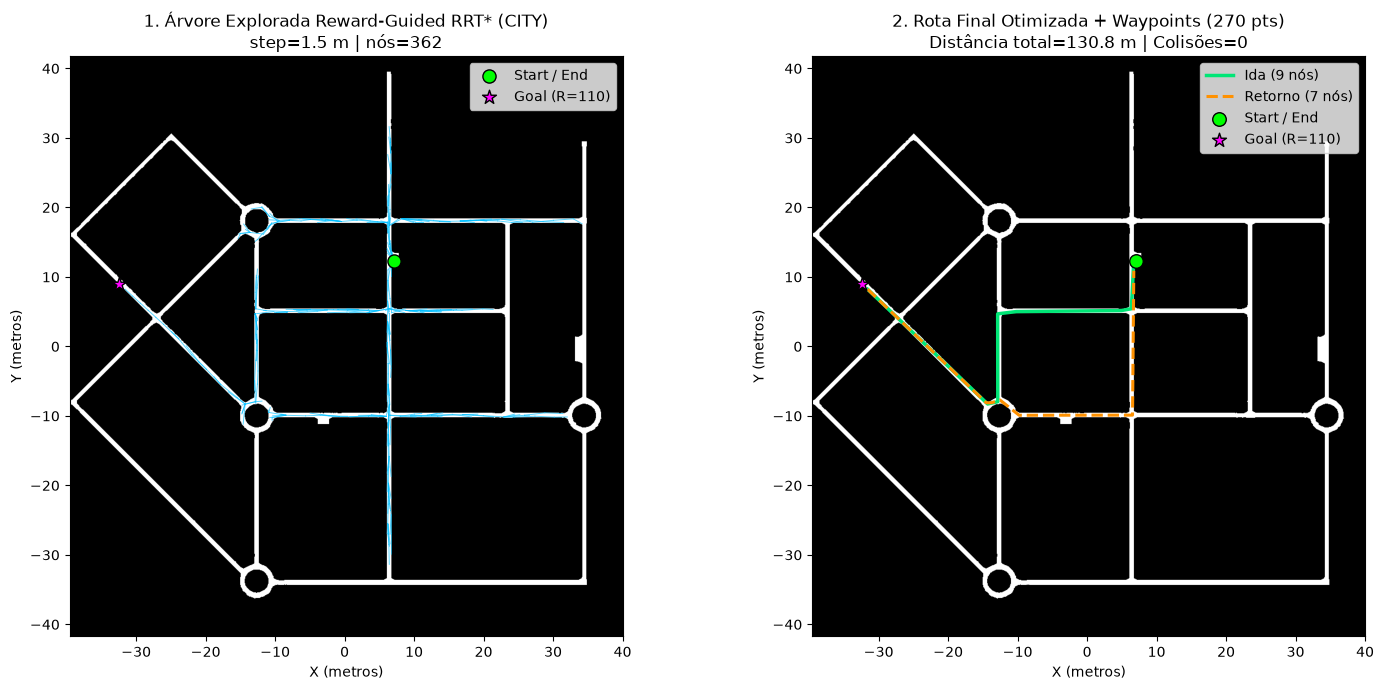

In [10]:
import csv
import matplotlib.pyplot as plt

WAYPOINT_SPACING_M = 0.5  # Espaçamento entre waypoints exportados para o Módulo 4 (metros)


def extract_and_resample_path(planner, spacing_m=0.5):
    """Extrai nós de ida e retorno do Reward_Guided_RRT e reamostra com (x, y, theta, phase)."""
    going_nodes = []
    for i, seg in enumerate(planner.going_path):
        going_nodes.extend(seg if i == 0 else seg[1:])
    returning_nodes = list(planner.returning_path)

    def _densify(nodes, phase_name):
        if len(nodes) < 2:
            return []
        pts = [np.asarray(n.position, dtype=float) for n in nodes]
        out = []
        for idx in range(len(pts) - 1):
            p1, p2 = pts[idx], pts[idx + 1]
            seg_len = float(np.linalg.norm(p2 - p1))
            if seg_len < 1e-6:
                continue
            theta = float(np.arctan2(p2[1] - p1[1], p2[0] - p1[0]))
            n_sub = max(1, int(np.ceil(seg_len / spacing_m)))
            ts = np.linspace(0.0, 1.0, n_sub, endpoint=False)
            for t in ts:
                p = p1 + t * (p2 - p1)
                out.append((float(p[0]), float(p[1]), theta, phase_name))
        last_theta = out[-1][2] if out else 0.0
        out.append((float(pts[-1][0]), float(pts[-1][1]), last_theta, phase_name))
        return out

    going_dense = _densify(going_nodes, "going")
    return_dense = _densify(returning_nodes, "returning")
    full_dense = going_dense + (return_dense[1:] if (going_dense and return_dense) else return_dense)
    return going_nodes, returning_nodes, going_dense, return_dense, full_dense


going_nodes, returning_nodes, going_dense, return_dense, full_waypoints = extract_and_resample_path(
    rrt_planner, spacing_m=WAYPOINT_SPACING_M
)

assert len(full_waypoints) > 0, "Nenhuma rota factível foi encontrada para exportar. Aumente MAX_ITER ou ajuste STEP_M."

# Exporta waypoints densificados (x, y, theta, phase) para o Módulo 4
wp_csv_path = os.path.join(PLAN_DIR, "waypoints_rrt.csv")
wp_npy_path = os.path.join(PLAN_DIR, "waypoints_rrt.npy")
route_fig_path = os.path.join(PLAN_DIR, "rota_rrt_planejada.png")

with open(wp_csv_path, "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["x", "y", "theta", "phase"])
    for x, y, th, phase in full_waypoints:
        writer.writerow([f"{x:.4f}", f"{y:.4f}", f"{th:.5f}", phase])

waypoints_rrt = np.array([[w[0], w[1], w[2]] for w in full_waypoints], dtype=np.float64)
np.save(wp_npy_path, waypoints_rrt)

# Verificação de segurança: garante que todos os waypoints exportados estão em pista livre
col_hits = sum(1 for x, y, _ in waypoints_rrt if rrt_planner.mapa.collision([x, y]))

print(f"Waypoints exportados com sucesso em {PLAN_DIR}:")
print(f"  - waypoints_rrt.csv : {len(full_waypoints)} pontos (espaçamento {WAYPOINT_SPACING_M:.2f} m)")
print(f"  - waypoints_rrt.npy : shape={waypoints_rrt.shape} [x, y, theta]")
print(f"  - Colisões detectadas nos waypoints: {col_hits}/{len(waypoints_rrt)}")

# Visualização em 2 painéis: Árvore Explorada vs Rota Final Calibrada
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
extent_cal = [CAL_BOUNDS[0], CAL_BOUNDS[1], CAL_BOUNDS[2], CAL_BOUNDS[3]]

# Painel 1: Árvore RRT* acumulada sobre o mapa calibrado
axes[0].imshow(1 - grid_rrt, cmap="gray", extent=extent_cal)
if rrt_planner.all_outward_tree is not None:
    for p1, p2 in rrt_planner.all_outward_tree.all_edges:
        axes[0].plot([p1[0], p2[0]], [p1[1], p2[1]], color="deepskyblue", lw=0.7, alpha=0.65)
axes[0].scatter(rrt_planner.start_pos[0], rrt_planner.start_pos[1], c="lime", edgecolors="black", s=90, zorder=6, label="Start / End")
for g in rrt_planner.goals:
    axes[0].scatter(g.pos[0], g.pos[1], c="magenta", edgecolors="black", s=110, marker="*", zorder=6, label=f"Goal (R={g.reward})")
n_tree_nodes = len(rrt_planner.all_outward_tree.nodes) if rrt_planner.all_outward_tree else 0
axes[0].set_title(f"1. Árvore Explorada Reward-Guided RRT* ({SCENARIO})\nstep={STEP_M} m | nós={n_tree_nodes}")
axes[0].set_xlabel("X (metros)")
axes[0].set_ylabel("Y (metros)")
axes[0].legend(loc="upper right")

# Painel 2: Rota final (ida + retorno) e waypoints exportados
axes[1].imshow(1 - grid_rrt, cmap="gray", extent=extent_cal)
if going_dense:
    g_arr = np.array([[p[0], p[1]] for p in going_dense])
    axes[1].plot(g_arr[:, 0], g_arr[:, 1], color="#00e676", lw=2.5, label=f"Ida ({len(going_nodes)} nós)")
if return_dense:
    r_arr = np.array([[p[0], p[1]] for p in return_dense])
    axes[1].plot(r_arr[:, 0], r_arr[:, 1], color="#ff9100", lw=2.2, ls="--", label=f"Retorno ({len(returning_nodes)} nós)")
axes[1].scatter(rrt_planner.start_pos[0], rrt_planner.start_pos[1], c="lime", edgecolors="black", s=95, zorder=6, label="Start / End")
for g in rrt_planner.goals:
    axes[1].scatter(g.pos[0], g.pos[1], c="magenta", edgecolors="black", s=110, marker="*", zorder=6, label=f"Goal (R={g.reward})")
axes[1].set_title(f"2. Rota Final Otimizada + Waypoints ({len(waypoints_rrt)} pts)\nDistância total={rrt_planner.total_budget_used:.1f} m | Colisões={col_hits}")
axes[1].set_xlabel("X (metros)")
axes[1].set_ylabel("Y (metros)")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.savefig(route_fig_path, dpi=150, bbox_inches="tight")
plt.show()